# 关注事件

**行为金融因子 —— 投资者注意力**

涨跌停事件数量和龙虎榜事件数量可作为投资者关注度的直接代理指标：

$$
\text{LimitEvent}_{i,t} = \sum_{d \in m} \left( \mathbb{1}_{\text{涨停},i,d} + \mathbb{1}_{\text{跌停},i,d} \right)
$$

其中：

* $\text{LimitEvent}_{i,t}$ 为股票 $i$ 在月度 $t$ 内发生涨停或跌停的总次数；
* $\mathbb{1}_{\text{涨停},i,d}$ 为指示函数，若股票 $i$ 在交易日 $d$ 涨停则取值为 1，否则为 0；
* $\mathbb{1}_{\text{跌停},i,d}$ 为指示函数，若股票 $i$ 在交易日 $d$ 跌停则取值为 1，否则为 0；
* $m$ 为月度交易日窗口。

$$
\text{DragonEvent}_{i,t} = \sum_{d \in m} \text{Dragon}_{i,d}
$$

其中：

* $\text{DragonEvent}_{i,t}$ 为股票 $i$ 在月度 $t$ 内登上龙虎榜的总次数；
* $\text{Dragon}_{i,d}$ 为股票 $i$ 在交易日 $d$ 登上龙虎榜的次数；
* $m$ 为月度交易日窗口。

## 应用方法

在实际投资组合构建中，可以每期买入上述涨跌停事件或龙虎榜事件数量排名前 50% 的股票构建投资组合，通过检验该组合的未来收益表现来评估关注事件类因子的选股能力。

## 因子说明

涨跌停股票和龙虎榜股票通常因其价格剧烈波动或受到监管机构公开披露而容易引起市场的广泛关注。这些特殊事件的发生，使得相关股票在短时间内暴露于大量投资者的视野中，成为市场关注的焦点。

因此，涨跌停事件数量和龙虎榜事件数量可以作为投资者关注度的有效代理指标。事件发生频率越高，表明该股票受市场关注的程度越高，后续可能引发更多的交易行为，并对股价产生相应的影响。

数据：日度涨跌停数据（日度收盘价、日度开盘价）、日度龙虎榜数据

In [1]:
import numpy as np
import pandas as pd
import rqdatac

from rqdatac import (
    all_instruments,
    get_price,
    get_trading_dates,
)


def _attention_event_get_ids(stock_ids):
    if stock_ids is None:
        return (
            all_instruments("CS")["order_book_id"]
            .dropna()
            .drop_duplicates()
            .tolist()
        )

    if isinstance(stock_ids, str):
        return [stock_ids]

    return list(dict.fromkeys(stock_ids))


def _attention_event_get_price_wide(
    order_book_ids,
    dates,
    limit_definition="close",
    batch_size=500,
):
    """下载涨跌停事件判断所需的日度行情宽表。"""
    fields = [
        "close",
        "volume",
        "limit_up",
        "limit_down",
    ]

    if limit_definition == "touch":
        fields.extend(["high", "low"])

    all_fields = {
        field: []
        for field in fields
    }

    for start in range(0, len(order_book_ids), batch_size):
        batch = order_book_ids[start:start + batch_size]

        # 涨跌停价是未复权价格，必须配合 adjust_type="none"
        raw = get_price(
            order_book_ids=batch,
            start_date=dates[0],
            end_date=dates[-1],
            frequency="1d",
            fields=fields,
            adjust_type="none",
            skip_suspended=False,
            expect_df=True,
        )

        if raw is None or raw.empty:
            continue

        for field in fields:
            if isinstance(raw.index, pd.MultiIndex):
                wide = raw[field].unstack("order_book_id")
            else:
                wide = raw[[field]].rename(
                    columns={field: batch[0]}
                )

            wide.index = pd.to_datetime(wide.index)

            all_fields[field].append(
                wide.reindex(index=dates, columns=batch)
            )

    result = {}

    for field in fields:
        if not all_fields[field]:
            raise RuntimeError(
                "未取得有效日度行情数据。"
            )

        wide = pd.concat(all_fields[field], axis=1)
        wide = wide.loc[:, ~wide.columns.duplicated()]

        result[field] = wide.reindex(
            index=dates,
            columns=order_book_ids,
        )

    return result


def _attention_event_get_dragon_daily(
    order_book_ids,
    dates,
):
    """
    构造龙虎榜事件次数：
    同一股票在同一日出现多条龙虎榜记录时，按多次事件计数。
    """
    if not hasattr(rqdatac, "get_abnormal_stocks"):
        raise RuntimeError(
            "当前 rqdatac 版本不支持 get_abnormal_stocks；"
            "请升级至包含龙虎榜日明细接口的版本。"
        )

    raw = rqdatac.get_abnormal_stocks(
        start_date=dates[0],
        end_date=dates[-1],
    )

    dragon_daily = pd.DataFrame(
        0.0,
        index=dates,
        columns=order_book_ids,
    )

    if raw is None or raw.empty:
        return dragon_daily

    temp = raw.reset_index()

    id_column = (
        "order_book_id"
        if "order_book_id" in temp.columns
        else "order_book_ids"
    )

    if id_column not in temp.columns or "date" not in temp.columns:
        raise ValueError("龙虎榜数据返回格式异常。")

    temp["date"] = pd.to_datetime(temp["date"])
    temp = temp[temp[id_column].isin(order_book_ids)]

    if temp.empty:
        return dragon_daily

    daily_count = (
        temp.groupby(["date", id_column])
        .size()
        .unstack(id_column)
    )

    return (
        daily_count
        .reindex(index=dates, columns=order_book_ids)
        .fillna(0.0)
    )


def calculate_attention_events_daily(
    start_date,
    end_date,
    window=20,
    candidate_ids=None,
    factor_type="both",
    limit_definition="close",
    batch_size=500,
):
    """
    关注事件因子

    参数：
        factor_type:
            "limit"  - 只输出 LimitEvent
            "dragon" - 只输出 DragonEvent
            "both"   - 同时输出两个因子

        limit_definition:
            "close" - 收盘价封在涨停或跌停价，默认且更严格
            "touch" - 日内最高/最低价触及涨停或跌停价

    输出：
        MultiIndex DataFrame
        index  : [date, order_book_id]
        column : LimitEvent 和/或 DragonEvent
    """
    if factor_type not in ("limit", "dragon", "both"):
        raise ValueError(
            "factor_type 仅支持 'limit'、'dragon'、'both'。"
        )

    if limit_definition not in ("close", "touch"):
        raise ValueError(
            "limit_definition 仅支持 'close'、'touch'。"
        )

    if window < 1:
        raise ValueError("window 必须为正整数。")

    candidate_ids = _attention_event_get_ids(candidate_ids)

    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(
                days=max(window * 3, 90)
            ),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("所选区间内没有交易日。")

    first_loc = calendar.get_loc(target_dates[0])
    last_loc = calendar.get_loc(target_dates[-1])

    if first_loc < window - 1:
        raise ValueError("历史交易日不足，无法计算滚动事件次数。")

    event_dates = calendar[
        first_loc - window + 1:last_loc + 1
    ]

    price_data = _attention_event_get_price_wide(
        order_book_ids=candidate_ids,
        dates=event_dates,
        limit_definition=limit_definition,
        batch_size=batch_size,
    )

    close = price_data["close"]
    volume = price_data["volume"]
    limit_up = price_data["limit_up"]
    limit_down = price_data["limit_down"]

    # 仅在实际交易的日期判断事件
    active = close.notna() & volume.gt(0)

    tolerance = 1e-6

    if limit_definition == "close":
        up_hit = (
            (close - limit_up).abs()
            <= tolerance + limit_up.abs() * tolerance
        )
        down_hit = (
            (close - limit_down).abs()
            <= tolerance + limit_down.abs() * tolerance
        )
    else:
        high = price_data["high"]
        low = price_data["low"]

        up_hit = (
            high >= limit_up - tolerance - limit_up.abs() * tolerance
        )
        down_hit = (
            low <= limit_down + tolerance + limit_down.abs() * tolerance
        )

    valid_limit_data = (
        active
        & limit_up.notna()
        & limit_down.notna()
    )

    # 同日若同时发生涨停、跌停，计为 2 次
    daily_limit_event = (
        up_hit.astype(float) + down_hit.astype(float)
    ).where(valid_limit_data)

    limit_factor = (
        daily_limit_event
        .rolling(window=window, min_periods=window)
        .sum()
        .reindex(target_dates)
        .where(active.reindex(target_dates))
    )

    factor_parts = []

    if factor_type in ("limit", "both"):
        factor_parts.append(
            limit_factor
            .stack(dropna=True)
            .rename("LimitEvent")
        )

    if factor_type in ("dragon", "both"):
        dragon_daily = _attention_event_get_dragon_daily(
            order_book_ids=candidate_ids,
            dates=event_dates,
        )

        # 停牌日不产生龙虎榜事件；不将停牌日纳入滚动窗口
        dragon_daily = dragon_daily.where(active)

        dragon_factor = (
            dragon_daily
            .rolling(window=window, min_periods=window)
            .sum()
            .reindex(target_dates)
            .where(active.reindex(target_dates))
        )

        factor_parts.append(
            dragon_factor
            .stack(dropna=True)
            .rename("DragonEvent")
        )

    result = pd.concat(factor_parts, axis=1)
    result.index = result.index.set_names(
        ["date", "order_book_id"]
    )

    return result

In [2]:
attention_events = calculate_attention_events_daily(
    start_date="2020-01-01",
    end_date="2025-12-31",
    window=20,
    candidate_ids=None,
    factor_type="both",
    limit_definition="close",
    batch_size=500,
)

attention_events.head()

LimitEvent  DragonEvent
date       order_book_id                         
2020-01-02 000001.XSHE           0.0          0.0
           000002.XSHE           0.0          0.0
           000004.XSHE           0.0          1.0
           000005.XSHE           0.0          0.0
           000006.XSHE           0.0          0.0

In [4]:
dragon_events_df = (
    attention_events["DragonEvent"]
    .unstack("order_book_id")
    .sort_index()
)

dragon_events_df.index = pd.to_datetime(dragon_events_df.index)
dragon_events_df.columns.name = "order_book_id"

dragon_events_df

order_book_id,000001.XSHE,000002.XSHE,000004.XSHE,000005.XSHE,000006.XSHE,000007.XSHE,000008.XSHE,000009.XSHE,000010.XSHE,000011.XSHE,...,688759.XSHG,688765.XSHG,688783.XSHG,603334.XSHG,603376.XSHG,603092.XSHG,301638.XSHE,688727.XSHG,001233.XSHE,001280.XSHE
date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,0.0,0.0,1.0,0.0,0.0,1.0,0.0,3.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,0.0,0.0,1.0,0.0,0.0,1.0,0.0,3.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,0.0,0.0,1.0,0.0,0.0,1.0,0.0,4.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,0.0,0.0,1.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-08,0.0,0.0,1.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-25,0.0,1.0,1.0,NaN,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,0.0,2.0,3.0,0.0,NaN
2025-12-26,0.0,1.0,1.0,NaN,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,0.0,1.0,3.0,0.0,NaN
2025-12-29,0.0,1.0,0.0,NaN,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,0.0,1.0,2.0,0.0,NaN


In [9]:
from rqfactor.notebook import factor_analysis

result_dragon_event = factor_analysis(
    f=dragon_events_df,
    period=1,
    shift=1,                    # 龙虎榜在收盘后公开，T+1 使用
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)

result_dragon_event.show()

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

...

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

Loading BokehJS ...

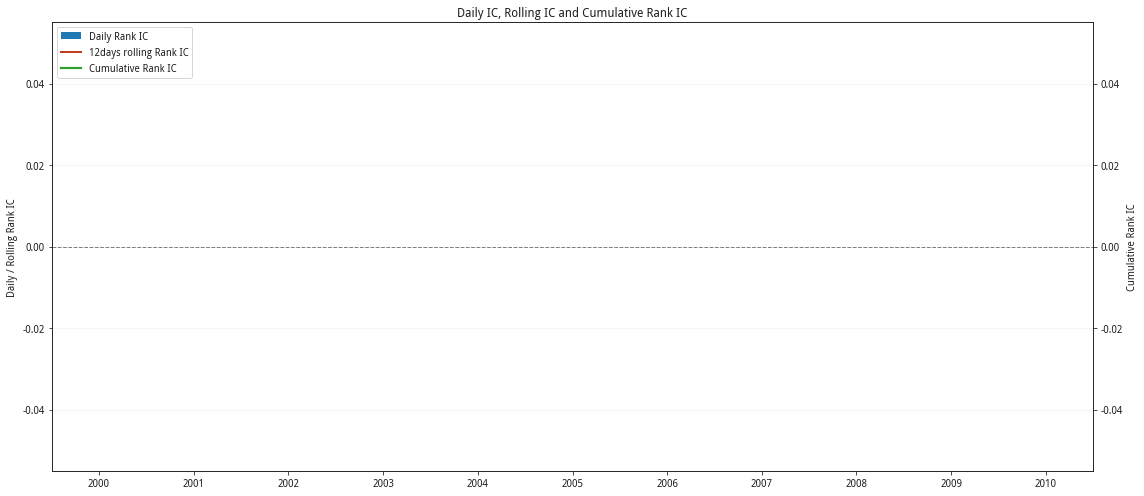

In [14]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_dragon_event.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()

In [5]:
limit_events_df = (
    attention_events["LimitEvent"]
    .unstack("order_book_id")
    .sort_index()
)

limit_events_df.index = pd.to_datetime(limit_events_df.index)
limit_events_df.columns.name = "order_book_id"

limit_events_df

order_book_id,000001.XSHE,000002.XSHE,000004.XSHE,000005.XSHE,000006.XSHE,000007.XSHE,000008.XSHE,000009.XSHE,000010.XSHE,000011.XSHE,...,688759.XSHG,688765.XSHG,688783.XSHG,603334.XSHG,603376.XSHG,603092.XSHG,301638.XSHE,688727.XSHG,001233.XSHE,001280.XSHE
date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0,1.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,0.0,0.0,0.0,0.0,0.0,1.0,0.0,3.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-08,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-25,0.0,1.0,4.0,NaN,0.0,2.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,NaN
2025-12-26,0.0,1.0,3.0,NaN,0.0,2.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,NaN
2025-12-29,0.0,1.0,2.0,NaN,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,NaN


In [10]:
from rqfactor.notebook import factor_analysis

result_limit_event = factor_analysis(
    f=limit_events_df,
    period=1,
    shift=1,                    # 龙虎榜在收盘后公开，T+1 使用
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)

result_limit_event.show()

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

...

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.

Loading BokehJS ...

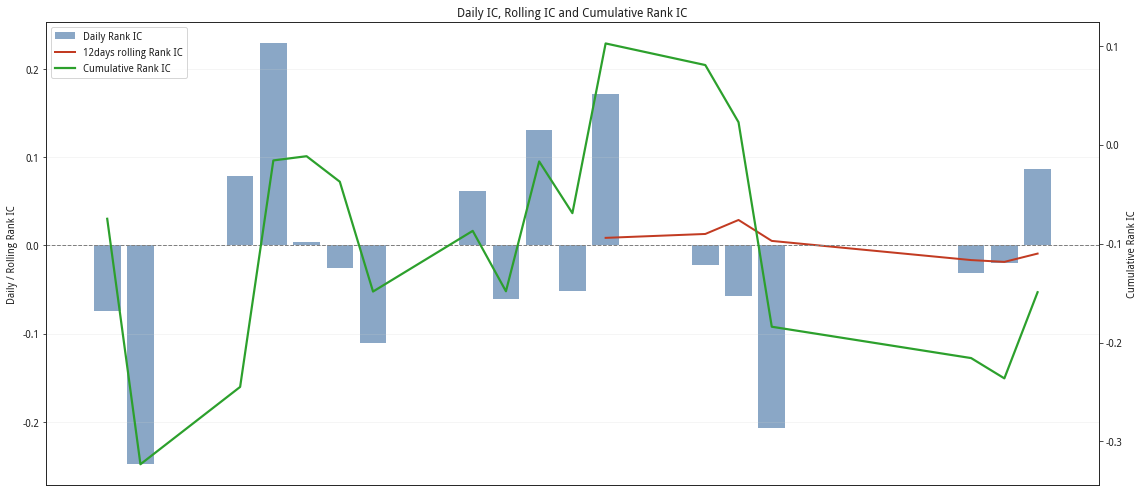

In [11]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_limit_event.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()

In [13]:
def event_factor_diagnostics(factor_data):
    diag = pd.DataFrame({
        "有效股票数": factor_data.notna().sum(axis=1),
        "非零事件股票数": factor_data.gt(0).sum(axis=1),
        "截面不同取值数量": factor_data.nunique(axis=1),
    })

    print("总交易日：", len(diag))
    print("因子恒定日：", (diag["截面不同取值数量"] <= 1).sum())
    print("有至少 1 只事件股的日期占比：",
          (diag["非零事件股票数"] >= 1).mean())
    print("有至少 5 只事件股的日期占比：",
          (diag["非零事件股票数"] >= 5).mean())

    return diag

dragon_diag = event_factor_diagnostics(dragon_events_df)
limit_diag = event_factor_diagnostics(limit_events_df)

总交易日： 1455
因子恒定日： 0
有至少 1 只事件股的日期占比： 1.0
有至少 5 只事件股的日期占比： 1.0
总交易日： 1455
因子恒定日： 0
有至少 1 只事件股的日期占比： 1.0
有至少 5 只事件股的日期占比： 1.0


> /usr/local/envs/Python3.9/lib/python3.9/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())

这是正常警告，不是程序崩溃。

`LimitEvent`、尤其 `DragonEvent` 是离散且稀疏的事件计数因子。很多交易日中，米筐实际参与检验的股票可能全部是：

```text
0 次事件
```

即该日截面因子值恒定。Spearman Rank IC 需要因子在同一天的股票间存在差异；全为 0 时相关系数没有定义，于是出现：

```text
SpearmanRConstantInputWarning
```

不要用随机扰动打破并列值；那会人为制造因子信息。

先检查有多少日期没有有效横截面差异：

```python
def event_factor_diagnostics(factor_data):
    diag = pd.DataFrame({
        "有效股票数": factor_data.notna().sum(axis=1),
        "非零事件股票数": factor_data.gt(0).sum(axis=1),
        "截面不同取值数量": factor_data.nunique(axis=1),
    })

    print("总交易日：", len(diag))
    print("因子恒定日：", (diag["截面不同取值数量"] <= 1).sum())
    print("有至少 1 只事件股的日期占比：",
          (diag["非零事件股票数"] >= 1).mean())
    print("有至少 5 只事件股的日期占比：",
          (diag["非零事件股票数"] >= 5).mean())

    return diag

dragon_diag = event_factor_diagnostics(dragon_event_data)
limit_diag = event_factor_diagnostics(limit_event_data)
```

然后在回测前剔除“截面恒定日”。对龙虎榜这种很稀疏的事件，我建议要求当天至少有 5 只股票的 20 日滚动事件数大于 0：

```python
def filter_event_factor(
    factor_data,
    min_valid_stocks=100,
    min_event_stocks=5,
):
    valid = (
        factor_data.notna().sum(axis=1).ge(min_valid_stocks)
        & factor_data.nunique(axis=1).ge(2)
        & factor_data.gt(0).sum(axis=1).ge(min_event_stocks)
    )
    return factor_data.loc[valid].copy()

dragon_event_for_test = filter_event_factor(
    dragon_event_data,
    min_event_stocks=5,
)

result_dragon_event = factor_analysis(
    f=dragon_event_for_test,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)
```

对 `LimitEvent`，可先放宽为：

```python
limit_event_for_test = filter_event_factor(
    limit_event_data,
    min_event_stocks=1,
)
```

如果 `DragonEvent` 经筛选后只剩下很少日期，说明它不适合做“每日全市场 Rank IC 因子”。这时更合适的研究方式是：

- 对“过去 20 日是否上过龙虎榜”做事件组与非事件组收益比较；
- 或只在事件发生后的 1、5、20 日观察超额收益；
- 或提高窗口，例如 `window=60`，增加非零股票覆盖度。

最后，如你仅想让输出不刷屏，可以隐藏警告；但应在先完成上面的覆盖度检查之后再这么做：

```python
import warnings
from scipy.stats import SpearmanRConstantInputWarning

warnings.filterwarnings(
    "ignore",
    category=SpearmanRConstantInputWarning,
)
```